# Probability, Conditional Probability, and Bayes’ Rule

**AI Mathematics · 3. Probability and Statistics**

Build the probability foundations used to reason about uncertainty, predictions, and evidence.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Define sample spaces, events, and independence.
- Compute conditional probabilities and Bayes’ rule.
- Distinguish random variables from observed samples.

In [1]:
import numpy as np

## 1. Events and probability
A sample space describes possible outcomes. An event is a subset of that space. Probabilities lie between 0 and 1, and mutually exclusive events have additive probabilities. These rules provide the consistency requirements for probabilistic models.

In [2]:
# A fair six-sided die
faces = np.arange(1, 7)
p_even = np.mean(faces % 2 == 0)
p_at_least_5 = np.mean(faces >= 5)
print("P(even):", p_even)
print("P(at least 5):", p_at_least_5)

P(even): 0.5
P(at least 5): 0.3333333333333333


## 2. Conditional probability and independence
Conditional probability is \(P(A|B)=P(A\cap B)/P(B)\) when \(P(B)>0\). Events are independent if \(P(A\cap B)=P(A)P(B)\). Independence is an assumption that should be justified; it does not follow merely because events refer to different variables.

In [3]:
p_disease = 0.01
p_positive_given_disease = 0.95
p_positive_given_no_disease = 0.05
p_positive = p_positive_given_disease*p_disease + p_positive_given_no_disease*(1-p_disease)
print("P(test positive):", p_positive)

# P(disease | positive) = P(positive | disease) P(disease) / P(positive)
p_disease_given_positive = p_positive_given_disease*p_disease/p_positive
print("P(disease | positive):", p_disease_given_positive)

P(test positive): 0.059000000000000004
P(disease | positive): 0.16101694915254236


## 3. Bayes’ rule
Bayes’ rule reverses a conditional probability: \(P(A|B)=P(B|A)P(A)/P(B)\). The prior \(P(A)\), likelihood \(P(B|A)\), and evidence \(P(B)\) combine to form the posterior \(P(A|B)\). The example above illustrates the base-rate effect: even a reasonably accurate test can have a modest positive predictive value when the event is rare.

In [4]:
def bayes(prior, likelihood, false_positive_rate):
    evidence = likelihood*prior + false_positive_rate*(1-prior)
    return likelihood*prior/evidence

for prevalence in [0.01, 0.10, 0.50]:
    print(prevalence, bayes(prevalence, 0.95, 0.05))

0.01 0.16101694915254236
0.1 0.6785714285714285
0.5 0.95


## 4. Random variables
A random variable maps outcomes to numbers. Its distribution describes probabilities before observing a particular sample. The expected value is a probability-weighted average, not necessarily a value the variable can actually take.

In [5]:
values = np.array([0, 1])
probabilities = np.array([0.7, 0.3])
expected_value = np.sum(values * probabilities)
variance = np.sum((values - expected_value)**2 * probabilities)
print("expected value:", expected_value)
print("variance:", variance)

expected value: 0.3
variance: 0.20999999999999996


## 5. Practical cautions
- A probability estimate can be poorly calibrated even when classification accuracy is high.
- Conditional probabilities require a nonzero conditioning event.
- The prior matters: ignoring class prevalence can badly distort interpretation.
- Independence assumptions should be validated, especially for repeated measurements or related samples.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: Bayes' rule with a labeled table

Bayes' rule reverses a conditional probability by combining a likelihood with a prior. A positive test result does not automatically imply a high probability of disease: when a condition is rare, false positives can account for many positive tests. This small table uses illustrative rates, not medical advice or a real diagnostic test.

P(condition | positive test) = 0.162


09_probability_bayes_and_random_variables.ipynb:cell14:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,test positive,test negative
actual state,,
condition present,0.019,0.001
condition absent,0.098,0.882


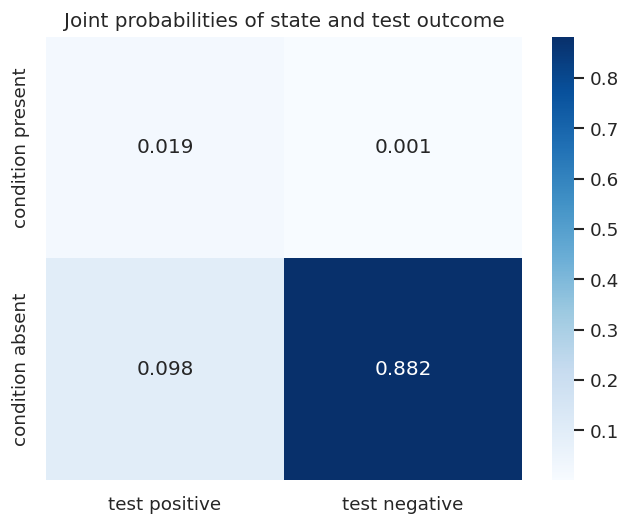

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_bayes_prevalence = 0.02
viz_bayes_sensitivity = 0.95
viz_bayes_specificity = 0.90
viz_bayes_table = pd.DataFrame({
    "test positive": [viz_bayes_prevalence*viz_bayes_sensitivity, (1-viz_bayes_prevalence)*(1-viz_bayes_specificity)],
    "test negative": [viz_bayes_prevalence*(1-viz_bayes_sensitivity), (1-viz_bayes_prevalence)*viz_bayes_specificity]
}, index=["condition present", "condition absent"])
display(viz_bayes_table.rename_axis("actual state").round(4))
viz_bayes_p_positive = viz_bayes_table.loc["condition present", "test positive"] / viz_bayes_table["test positive"].sum()
print("P(condition | positive test) =", round(float(viz_bayes_p_positive), 3))
sns.heatmap(viz_bayes_table, annot=True, fmt=".3f", cmap="Blues")
plt.title("Joint probabilities of state and test outcome"); plt.show()

### Simulate conditional probability

Simulation approximates probability by counting outcomes. Sampling variation means that the simulated estimate will not usually equal the theoretical probability exactly, especially for rare events or small samples.

In [7]:
viz_bayes_rng = np.random.default_rng(17)
viz_bayes_n = 100_000
viz_bayes_actual = viz_bayes_rng.random(viz_bayes_n) < viz_bayes_prevalence
viz_bayes_positive = np.where(viz_bayes_actual, viz_bayes_rng.random(viz_bayes_n) < viz_bayes_sensitivity, viz_bayes_rng.random(viz_bayes_n) < (1-viz_bayes_specificity))
viz_bayes_simulated = viz_bayes_actual[viz_bayes_positive].mean()
print("theoretical posterior:", round(float(viz_bayes_p_positive), 4))
print("simulated posterior:", round(float(viz_bayes_simulated), 4))
viz_bayes_rates = pd.DataFrame({"actual": viz_bayes_actual, "positive": viz_bayes_positive})
display(pd.crosstab(viz_bayes_rates["actual"], viz_bayes_rates["positive"], normalize="all").round(4))

theoretical posterior: 0.1624
simulated posterior: 0.1646


positive,False,True
actual,,
False,0.8818,0.0979
True,0.0010,0.0193


## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: A class has 12 students, 7 of whom passed. What is the empirical pass rate?

In [8]:
passed, total = 7, 12
print(passed / total)

0.5833333333333334


### Exercise 2
Exercise 2: Compute P(A|B) when P(A∩B)=0.12 and P(B)=0.30.

In [9]:
print(0.12 / 0.30)

0.4


## Key takeaways
- Bayes’ rule updates prior belief using the likelihood and observed evidence.
- Conditional probability is not symmetric: P(A|B) may differ greatly from P(B|A).
- Base rates and sampling assumptions are central to reliable probabilistic reasoning.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.